
 Logistic Regression
Accuracy : 0.9737
Precision: 0.9859
Recall   : 0.9722
F1-Score : 0.979

 Perceptron
Accuracy : 0.9386
Precision: 0.971
Recall   : 0.9306
F1-Score : 0.9504


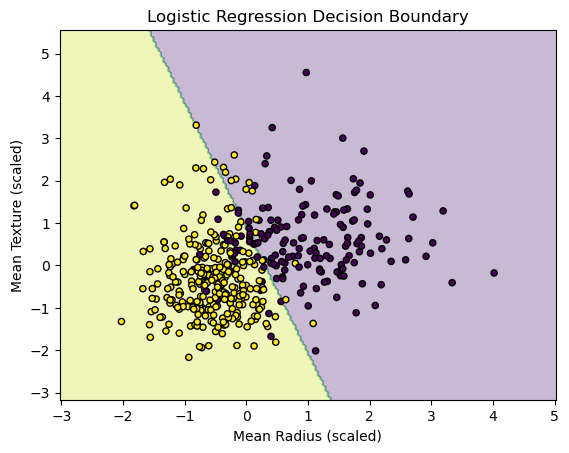

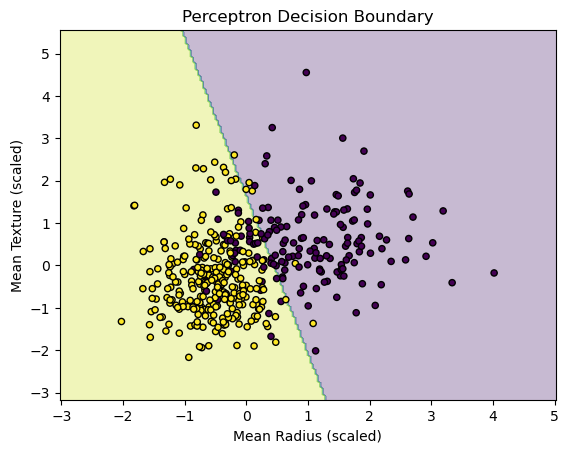

In [2]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 1. Load Breast Cancer dataset
data = load_breast_cancer()
X = data.data
y = data.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


# 2. Logistic Regression from scratch
class LogisticRegressionScratch:
    def __init__(self, lr=0.01, epochs=2000):
        self.lr = lr
        self.epochs = epochs

    def sigmoid(self, z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        n, m = X.shape
        self.w = np.zeros(m)
        self.b = 0

        for _ in range(self.epochs):
            z = np.dot(X, self.w) + self.b
            p = self.sigmoid(z)

            dw = np.dot(X.T, (p - y)) / n
            db = np.mean(p - y)

            self.w -= self.lr * dw
            self.b -= self.lr * db

    def predict(self, X):
        p = self.sigmoid(np.dot(X, self.w) + self.b)
        return (p >= 0.5).astype(int)


# 3. Perceptron from scratch
class PerceptronScratch:
    def __init__(self, lr=0.01, epochs=1000):
        self.lr = lr
        self.epochs = epochs

    def fit(self, X, y):
        n, m = X.shape
        self.w = np.zeros(m)
        self.b = 0

        # Convert labels from 0,1 to -1,+1
        y_new = np.where(y == 0, -1, 1)

        for _ in range(self.epochs):
            for i in range(n):
                if y_new[i] * (np.dot(X[i], self.w) + self.b) <= 0:
                    self.w += self.lr * y_new[i] * X[i]
                    self.b += self.lr * y_new[i]

    def predict(self, X):
        return (np.dot(X, self.w) + self.b >= 0).astype(int)


# 4. Train both models
lr_model = LogisticRegressionScratch()
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

p_model = PerceptronScratch()
p_model.fit(X_train, y_train)
y_pred_p = p_model.predict(X_test)


# 5. Evaluate models
def evaluate(name, y_true, y_pred):
    print("\n", name)
    print("Accuracy :", round(accuracy_score(y_true, y_pred), 4))
    print("Precision:", round(precision_score(y_true, y_pred), 4))
    print("Recall   :", round(recall_score(y_true, y_pred), 4))
    print("F1-Score :", round(f1_score(y_true, y_pred), 4))


evaluate("Logistic Regression", y_test, y_pred_lr)
evaluate("Perceptron", y_test, y_pred_p)


# 6. Plot decision boundaries using two features
X2 = data.data[:, [0, 1]]  # Mean radius and mean texture

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.2, random_state=42, stratify=y
)

scaler2 = StandardScaler()
X2_train = scaler2.fit_transform(X2_train)
X2_test = scaler2.transform(X2_test)

lr2 = LogisticRegressionScratch()
lr2.fit(X2_train, y2_train)

p2 = PerceptronScratch()
p2.fit(X2_train, y2_train)


def plot_boundary(model, X, y, title):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 200),
        np.linspace(y_min, y_max, 200)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid).reshape(xx.shape)

    plt.contourf(xx, yy, Z, alpha=0.3)
    plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors="k", s=20)
    plt.xlabel("Mean Radius (scaled)")
    plt.ylabel("Mean Texture (scaled)")
    plt.title(title)
    plt.show()


plot_boundary(lr2, X2_train, y2_train, "Logistic Regression Decision Boundary")
plot_boundary(p2, X2_train, y2_train, "Perceptron Decision Boundary")



